In [2]:
#Initial setup and settings. 
from IPython.core.interactiveshell import InteractiveShell 
InteractiveShell.ast_node_interactivity = "all"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import os
import joblib
print("Scikit-Learn",sklearn.__version__)

from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report
from scipy.stats import loguniform, randint
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix
from sklearn.metrics import confusion_matrix


#--settings---
LABEL_LAG_CUTOFF = "2026-09-01"   # evaluations on/after this date may not have violations determined yet
RANDOM_STATE = 42
TEST_SIZE = 0.30
CV_FOLDS = 3
TARGET = "VIOL_GROUP"
CAT_FEATURES = ["EVAL_TYPE_DESC", "EVAL_LEAD_AGENCY","EVAL_ACTIVITY_LOCATION"]
NUM_FEATURES = ["EVAL_MONTH"]
FEATURES = CAT_FEATURES + NUM_FEATURES

Scikit-Learn 1.4.2


# Part 1: Data Preperation 



### Load data and drop cloumns

In [2]:
rcra_df = pd.read_csv("data/PIPELINE_RCRA_00_COMPLETE.csv")

# Dropping every row with any missing value removed too much data. Some missing values are
# actually informative (e.g., a missing enforcement field means no action was taken).
# Violation type is my target, so I only drop rows where it is missing.
rcra_df2 = rcra_df.dropna(subset=['VIOL_TYPE'])

# Dropping features that are leakage, irrelevant (weak bearing on target), or redundant.
rcra_df3 = rcra_df2.drop(columns=['SOURCE_ID', 'REGISTRY_ID', 'EVAL_IDENTIFIER', 'ENF_KEY', 'CASE_ID', 'PENALTY_AMOUNT',
                                  'FOUND_VIOLATION', 'VIOL_SEQ', 'VIOL_ACTIVITY_LOCATION', 'VIOL_DETERMINED_BY_AGENCY',
                                  'VIOL_AGENCY', 'VIOL_DETERMINED_DATE', 'ACTUAL_RTC_DATE', 'VIOL_RTC_DATE', 'ENF_TYPE_DESC',
                                  'ENF_ACTION_DATE', 'ENF_COMP_ACTION_COST', 'ENF_ACTIVITY_LOCATION', 'ENF_AGENCY', 'ISN', 'RCR_NAME',
                                  'EVAL_TYPE', 'OFFICIAL_FLAG', 'PIPELINE_FLAG', 'ENF_IDENTIFIER'])

### Filter to 2017 onward

In [3]:
# While conducting early EDA within the CSV file directly, I found dates going all the way back to the 80s.
# Goal: keep evaluations from 2017 onward (most relevant RCRA regulations).
rcra_df3['EVAL_DATE'] = pd.to_datetime(rcra_df3['EVAL_DATE'])
rcra_df4 = rcra_df3[rcra_df3['EVAL_DATE'].dt.year >= 2017].copy()

# Checking the filter.
print(rcra_df4['EVAL_DATE'].min(), len(rcra_df3), len(rcra_df4))

2017-01-01 00:00:00 455579 438819


### Group violatons types into classes

In [4]:
# Goal: each evaluation gets one label (one ISN_RCR_EVAL with a single VIOL_TYPE). 121 classes are too many,
# so group them into 6-8 categories by CFR (Code of Federal Regulations) citation,
# including separate "No Violation" and "Other" classes.
def group_viol(v):
    if v in ("No Violation Identified", "No New Violations Reported"):
        return "No Violation"
    if v.startswith("262.A"):
        return "Generators - General"
    if v.startswith("262.C"):
        return "Generators - Pre-transport"
    if v.startswith(("262.B", "262.D")):
        return "Generators - Manifest/Records"
    if v.startswith(("273.", "279.")):
        return "Universal Waste / Used Oil"
    if v.startswith(("XXS", "FSS", "PCR")):
        return "State/Federal Statute or Permit Condition"
    if v.startswith(("264.", "265.", "270.")):
        return "TSD / Permits"
    if v.startswith("262.M"):
        return "Emergency Preparedness"
    if v.startswith(("268.A", "261.A")):
        return "LDR / Waste Identification"
    return "Other"

# "Undetermined" shouldn't be a class for model training/testing since the outcome is unknown.
rcra_df4 = rcra_df4[
    (rcra_df4['VIOL_TYPE'] != 'Undetermined') & rcra_df4['VIOL_TYPE'].notna()].copy()

# Verifying that 'Undetermined' and blanks were removed (both should print 0).
print((rcra_df4['VIOL_TYPE'] == 'Undetermined').sum(), rcra_df4['VIOL_TYPE'].isna().sum())

rcra_df4['VIOL_GROUP'] = rcra_df4['VIOL_TYPE'].map(group_viol)

0 0


### Collapse to one row per evaluation

In [5]:
# Before collapsing, keep one row per distinct evaluation (ISN_RCR_EVAL) and violation type (VIOL_TYPE).
rcra_df4 = rcra_df4.drop_duplicates(subset=['ISN_RCR_EVAL', 'VIOL_TYPE'])

# Flag evaluations that have at least one real violation, and map it onto the rows.
violation_per_eval = (rcra_df4['VIOL_GROUP'] != 'No Violation').groupby(rcra_df4['ISN_RCR_EVAL']).any()
rcra_df4['HAS_VIOLATION'] = rcra_df4['ISN_RCR_EVAL'].map(violation_per_eval)

# Drop rows labeled "No Violation" when the same evaluation also has a real violation.
mask = (rcra_df4['VIOL_GROUP'] == 'No Violation') & (rcra_df4['HAS_VIOLATION'])
rcra_df4 = rcra_df4[~mask].copy()

# Distinct groups per violating evaluation (shows how often the tie-break is needed).
viol_only = rcra_df4[rcra_df4['HAS_VIOLATION']]
groups_per_eval = viol_only.groupby('ISN_RCR_EVAL')['VIOL_GROUP'].nunique()
print(groups_per_eval.value_counts().sort_index())
print(groups_per_eval.value_counts(normalize=True).sort_index().round(3))

# Now count the rows each evaluation has in each group, look up how big each group is overall,
# sort so the "winning" row is first within each evaluation (i.e., confirmed violation),
# keep one row per evaluation, and remove the helper columns.
rcra_df4['GROUP_COUNT'] = rcra_df4.groupby(['ISN_RCR_EVAL', 'VIOL_GROUP'])['VIOL_GROUP'].transform('size')
group_sizes = rcra_df4['VIOL_GROUP'].value_counts()
rcra_df4['GROUP_SIZE'] = rcra_df4['VIOL_GROUP'].map(group_sizes)
rcra_df4 = rcra_df4.sort_values(['ISN_RCR_EVAL', 'GROUP_COUNT', 'GROUP_SIZE'], ascending=[True, False, True])
rcra_df4 = (rcra_df4.drop_duplicates(subset='ISN_RCR_EVAL', keep='first')
                    .drop(columns=['GROUP_COUNT', 'GROUP_SIZE'])
                    .copy())

# Run checks.
print(len(rcra_df4), rcra_df4['ISN_RCR_EVAL'].nunique())
print(rcra_df4['VIOL_GROUP'].value_counts())
print(rcra_df4['VIOL_GROUP'].value_counts(normalize=True).round(3))

VIOL_GROUP
1    27008
2    14742
3     7802
4     4580
5     1538
6      452
7       90
8       18
Name: count, dtype: int64
VIOL_GROUP
1    0.480
2    0.262
3    0.139
4    0.081
5    0.027
6    0.008
7    0.002
8    0.000
Name: proportion, dtype: float64
191500 191500
VIOL_GROUP
No Violation                                 135270
Universal Waste / Used Oil                     9860
State/Federal Statute or Permit Condition      9088
Generators - Pre-transport                     7528
Generators - Manifest/Records                  7506
Generators - General                           6978
TSD / Permits                                  6779
LDR / Waste Identification                     3344
Emergency Preparedness                         3028
Other                                          2119
Name: count, dtype: int64
VIOL_GROUP
No Violation                                 0.706
Universal Waste / Used Oil                   0.051
State/Federal Statute or Permit Condition    0.047
Generato

### Cut off the label lag and add the month feature

In [6]:
# NOTE: cut off dates where there is a lag in violation determination. It would not be fair to train/test
# the model on evaluations whose violations have not been determined yet. They would show as "No Violation"
# only because of a lag in paperwork.
rcra_df4 = rcra_df4[rcra_df4['EVAL_DATE'] < LABEL_LAG_CUTOFF].copy()
rcra_df4['EVAL_MONTH'] = rcra_df4['EVAL_DATE'].dt.month
print(rcra_df4.shape)

(191030, 9)


# Part 2: Modeling

In [ ]:
#Raw columns, lable encoding, and splitting. 
model_df = rcra_df4[FEATURES + [TARGET]].copy()
print(model_df.shape)
print(model_df.isna().sum())

X = model_df[FEATURES]
le = LabelEncoder()
y = le.fit_transform(model_df[TARGET])
class_names = list(le.classes_)

X_train, X_test, y_train, y_test = train_test_split(
    X,y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
print(X_train.shape, X_test.shape)

(191030, 5)
EVAL_TYPE_DESC            0
EVAL_LEAD_AGENCY          0
EVAL_ACTIVITY_LOCATION    0
EVAL_MONTH                0
VIOL_GROUP                0
dtype: int64
(133721, 4) (57309, 4)


In [ ]:
#Building the preprocessor.

#the data set that was built for this was already preprocessed and missing data handled. Be sure to evaluate any new data for
#missing i.e - "df.isna().mean". Do not impute the tartget variable. You can choose whether to use imputation or not. 
def make_preprocessor ():
    cat_pipe = Pipeline ([
        ('impute', SimpleImputer(strategy="most_frequent")),
        ('onehot', OneHotEncoder(handle_unknown="infrequent_if_exist",
                                 min_frequency= 20, sparse_output=False)),
    ])
    num_pipe = Pipeline([
        ('impute', SimpleImputer(strategy="median")),
        ('scale', MinMaxScaler())
    ])
    return ColumnTransformer(
        [('cat', cat_pipe,CAT_FEATURES), ('num', num_pipe, NUM_FEATURES)],
        verbose_feature_names_out=False)

prep = make_preprocessor()
Xt = prep.fit_transform (X_train)
print (Xt.shape)
print(prep.get_feature_names_out()[:8])
scaler = prep.named_transformers_['num'].named_steps['scale']
print(scaler.data_min_,scaler.data_max_)

(133721, 70)
['EVAL_TYPE_DESC_Case Development Inspection'
 'EVAL_TYPE_DESC_Compliance Assistance Visit'
 'EVAL_TYPE_DESC_Compliance Evaluation Inspection'
 'EVAL_TYPE_DESC_Compliance Schedule Evaluation'
 'EVAL_TYPE_DESC_Corrective Action Compliance Evaluation'
 'EVAL_TYPE_DESC_Facility Self Disclosure'
 'EVAL_TYPE_DESC_Financial Record Review'
 'EVAL_TYPE_DESC_Focused Compliance Inspection']
[1.] [12.]


In [ ]:
#Wrap preprocessing and a model into on Pipeline, and set the baseline. 

def make_pipe(model):
    return Pipeline([('prep',make_preprocessor()),('model',model)])

def score (pipe,X_,y_):
    pred = pipe.predict(X_)
    return {'accuracy': accuracy_score(y_, pred),
            'balanced_acc': balanced_accuracy_score(y_,pred),
            'macro_f1': f1_score(y_, pred, average='macro')}

dummy = make_pipe (DummyClassifier(strategy="most_frequent")).fit(X_train, y_train)
print({k: round(v, 3) for k, v in score(dummy, X_test, y_test).items()})

{'accuracy': 0.706, 'balanced_acc': 0.1, 'macro_f1': 0.083}


In [ ]:
#Cross-validate several models, with and without class weights

skf = StratifiedKFold (CV_FOLDS, shuffle=True, random_state = RANDOM_STATE)
scoring = {'macro_f1': 'f1_macro', 'balanced_acc': 'balanced_accuracy','accuracy': 'accuracy'}

candidates = {
    'logreg, no weights':               LogisticRegression(max_iter=300),
    'logreg, balanced':                 LogisticRegression(max_iter=300, class_weight='balanced'),
    'random forest, balanced':          RandomForestClassifier(n_estimators= 150, min_samples_leaf = 20, 
                                            class_weight= 'balanced_subsample', n_jobs=2,
                                            random_state=RANDOM_STATE),
    'hist gradient boost, no weights':   HistGradientBoostingClassifier (max_iter=150, random_state=RANDOM_STATE), 
    'hist gradient boost, balanced':    HistGradientBoostingClassifier (max_iter=150, class_weight = "balanced", 
                                            random_state= RANDOM_STATE)
}

rows = []
for name, model in candidates.items (): 
    r = cross_validate (make_pipe(model), X_train, y_train, cv = skf, scoring = scoring, n_jobs=1)
    rows.append({'model':name, 
                'macro_f1': r['test_macro_f1'].mean(),'macro_f1_sd': r['test_macro_f1'].std(),
                'balanced_acc': r['test_balanced_acc'].mean(), 'accuracy': r['test_accuracy'].mean()})
    print(f"{name:<34} macro-F1 = {rows[-1]['macro_f1']:.3f}", flush= True)

cv_table = pd.DataFrame(rows).round(3)
cv_table

logreg, no weights                 macro-F1 = 0.130
logreg, balanced                   macro-F1 = 0.209
random forest, balanced            macro-F1 = 0.232
hist gradient boost, no weights    macro-F1 = 0.182
hist gradient boost, balanced      macro-F1 = 0.237


,model,macro_f1,macro_f1_sd,balanced_acc,accuracy
0,"logreg, no weights",0.130,0.002,0.126,0.707
1,"logreg, balanced",0.209,0.007,0.318,0.381
2,"random forest, balanced",0.232,0.003,0.341,0.396
3,"hist gradient boost, no weights",0.182,0.004,0.157,0.721
4,"hist gradient boost, balanced",0.237,0.003,0.350,0.381


In [ ]:
#Tune the best peforming model with RandomSearchCV

N_ITER = 3  #this is just the first pass; we can raise it later. 

search_space = {
    'model__learning_rate': loguniform (0.03, 0.3),
    'model__max_iter': randint(80,250),
    'model__max_leaf_nodes': randint(8,64), 
    'model__min_samples_leaf': randint(20,200),
    'model__l2_regularization': loguniform(1e-3, 10),
}

search = RandomizedSearchCV(
    make_pipe (HistGradientBoostingClassifier(class_weight='balanced',random_state=RANDOM_STATE)),
    search_space, n_iter=N_ITER, scoring = 'f1_macro', cv=skf,
    refit = True, random_state=RANDOM_STATE, n_jobs=1)
search.fit(X_train, y_train)

print('best CV macro_F1:', round(search.best_score_, 4))
print (search.best_params_)
best_pipe = search.best_estimator_

RandomizedSearchCV(cv=StratifiedKFold(n_splits=3, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('prep',
                                              ColumnTransformer(transformers=[('cat',
                                                                               Pipeline(steps=[('impute',
                                                                                                SimpleImputer(strategy='most_frequent')),
                                                                                               ('onehot',
                                                                                                OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                                                              min_frequency=20,
                                                                                                              sparse_output=False))]),
                                                                               ['EVAL_TYPE_DESC',
                                                                                'EVAL_LEAD_...
                                        'model__learning_rate': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x000002DBBE87D590>,
                                        'model__max_iter': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x000002DBBE8C6210>,
                                        'model__max_leaf_nodes': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x000002DBBE87D490>,
                                        'model__min_samples_leaf': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x000002DBBE8C6510>},
                   random_state=42, scoring='f1_macro')

best CV macro_F1: 0.2341
{'model__l2_regularization': 0.02161894240657444, 'model__learning_rate': 0.0416857934827831, 'model__max_iter': 210, 'model__max_leaf_nodes': 29, 'model__min_samples_leaf': 72}


In [ ]:
# Evaluate on the test set. 

unweighted = make_pipe(HistGradientBoostingClassifier(max_iter= 150, random_state= RANDOM_STATE)).fit(X_train, y_train)

results = pd.DataFrame({
    'majority baseline': score(dummy, X_test, y_test),
    'no class weights': score(unweighted, X_test, y_test),
    'tuned + class weights': score(best_pipe, X_test, y_test),
}).T.round(3)
display(results)

pred = best_pipe.predict(X_test)
print(classification_report(y_test, pred, target_names = class_names, digits=2, zero_division=0))

,accuracy,balanced_acc,macro_f1
majority baseline,0.706,0.100,0.083
no class weights,0.722,0.160,0.187
tuned + class weights,0.383,0.356,0.239


                                           precision    recall  f1-score   support

                   Emergency Preparedness       0.07      0.58      0.12       906
                     Generators - General       0.10      0.32      0.15      2090
            Generators - Manifest/Records       0.41      0.24      0.31      2251
               Generators - Pre-transport       0.17      0.65      0.27      2257
               LDR / Waste Identification       0.17      0.37      0.23      1002
                             No Violation       0.97      0.40      0.57     40460
                                    Other       0.03      0.18      0.05       634
State/Federal Statute or Permit Condition       0.24      0.30      0.27      2723
                            TSD / Permits       0.13      0.27      0.18      2032
               Universal Waste / Used Oil       0.24      0.26      0.25      2954

                                 accuracy                           0.38     57309
  

Text(0.5, 0, 'Recall (share of actual cases found)')

Text(0.5, 1.0, 'Per-class recall on the test set')

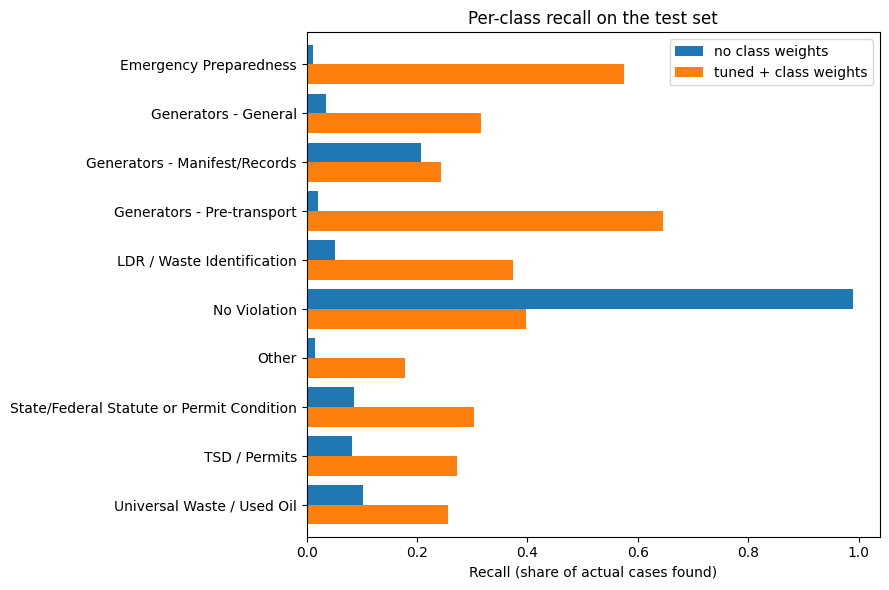

Text(0, 0, '0.58')

Text(1, 0, '0.05')

Text(2, 0, '0.00')

Text(3, 0, '0.03')

Text(4, 0, '0.02')

...

Text(8, 9, '0.06')

Text(9, 9, '0.26')

Text(0.5, 0, 'Predicted')

Text(0, 0.5, 'Actual (row-normalized: diagonal = recall)')

Text(0.5, 1.0, 'Tuned, class-weighted model')

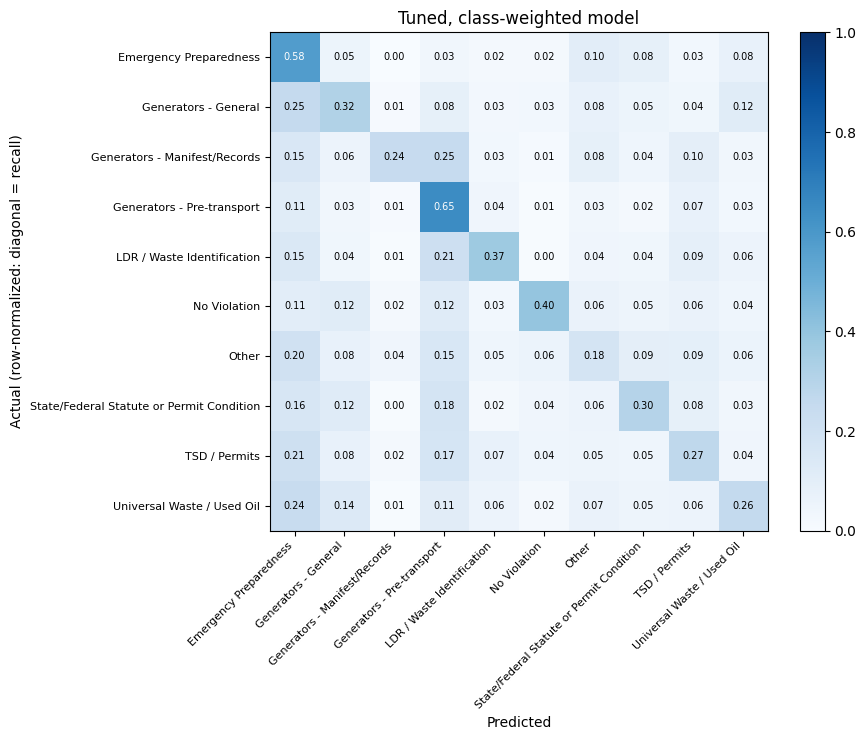

In [ ]:
#Charts for visualizing the trade offs. 
%matplotlib inline

#Barchart:
rep_before = classification_report(y_test, unweighted.predict(X_test),
                                   target_names=class_names, output_dict=True, zero_division=0)
rep_after = classification_report(y_test, pred,
                                  target_names=class_names, output_dict=True, zero_division=0)

recall_df = pd.DataFrame({
    "no class weights":      [rep_before[c]["recall"] for c in class_names],
    "tuned + class weights": [rep_after[c]["recall"] for c in class_names],
}, index=class_names)

ax = recall_df.plot.barh(figsize=(9, 6), width=0.8)
ax.invert_yaxis()
ax.set_xlabel("Recall (share of actual cases found)")
ax.set_title("Per-class recall on the test set")
plt.tight_layout()
plt.show()

#Confusion matrix:

cm = confusion_matrix(y_test, pred, labels=range(len(class_names)), normalize="true")
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(class_names)), class_names, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(class_names)), class_names, fontsize=8)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > 0.5 else "black")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual (row-normalized: diagonal = recall)")
ax.set_title("Tuned, class-weighted model")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()

In [ ]:
#Permuation Importance

perm = permutation_importance(
    best_pipe, X_test, y_test,
    scoring="f1_macro",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

perm_df = (
    pd.DataFrame({
        "feature": X_test.columns,
        "importance_mean": perm.importances_mean,
        "importance_std": perm.importances_std,
    })
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)
perm_df

,feature,importance_mean,importance_std
0,EVAL_ACTIVITY_LOCATION,0.129525,0.001381
1,EVAL_TYPE_DESC,0.095687,0.001379
2,EVAL_LEAD_AGENCY,0.032937,0.000265
3,EVAL_MONTH,0.029041,0.000904


In [15]:
#9. We save and reload the model. Exact match test.  

os.makedirs("models", exist_ok=True)

artifact = {
    "pipeline": best_pipe,
    "label_encoder": le,
    "features": FEATURES,
    "sklearn_version": sklearn.__version__,
}
joblib.dump(artifact, "models/champion.joblib", compress=3)

loaded = joblib.load("models/champion.joblib")
pred_loaded = loaded["pipeline"].predict(X_test)

print(np.array_equal(pred_loaded, best_pipe.predict(X_test)))
print(loaded["label_encoder"].inverse_transform(pred_loaded[:5]))



['models/champion.joblib']

True
['Generators - Pre-transport' 'Emergency Preparedness' 'No Violation'
 'Emergency Preparedness' 'Universal Waste / Used Oil']
